In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ruby1290/ai-usage-impact-on-student-and-professionals/AI_Usage_and_Impact_on_Students_and_Professionals.csv


In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/kaggle/input/datasets/ruby1290/ai-usage-impact-on-student-and-professionals/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

In [4]:
df.head(10)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes
5,U0225,19,NaN,United States,Student,Undergraduate,Business Analytics Student,774,Meta AI,Data Analysis,1.5,"Statistical analysis on datasets, data visuali...",0,5.0,3.0,6.0,2.9,7.4,No
6,U0246,32,Male,france,Professional,Bachelor's,Développeur Full Stack,4466,ChatGPT,Coding,1.2,"Automated code review with AI-powered linters,...",20,3.0,2.0,5.0,6.6,6.4,Yes
7,U0177,32,Male,Philippines,Professional,High School,Social Media Content Creator,486,ChatGPT,Content Creation,2,Creating Instagram/TikTok captions with AI wri...,0,6.5,2.0,5.0,3.2 hrs,6.4,Yes
8,U0207,16,Male,Philippines,Student,Undergraduate,Digital Media Production Student,132,Claude,Content Creation,1.6 hrs,"Creating YouTube video scripts, Designing soci...",30,4.7,4.0,6.0,3.8,3.8,Yes
9,U0167,40,male,india,Professional,High School,NaN,1595,ChatGPT,Writing,1.7,"Email copywriting, Social media post creation,...",10,NaN,2.0,5.0,7.5,9.4,Maybe


In [5]:
df.tail(10)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
290,U0287,22,Other,India,Student,undergrad,Mechanical Engineering Student,0,Meta AI,Studying,2.4,Generating solved examples for thermodynamics ...,20,3.4,4.0,6.0,4.8,6.2,No
291,U0147,39,Male,brazil,Professional,Diploma,Analista de Dados,894,ChatGPT,Data Analysis,2.8,NaN,20,7.9,4.0,9.0,3.9,9.2,Yes
292,U0134,27,Other,Canada,Student,Undergraduate,Digital Media Production Student,675,Claude,Content Creation,1.2,"Generating video scripts and storyboards, Crea...",20,4.1,3.0,6.0,1.1,7.6,Yes
293,U0158,31,Male,Australia,Student,Undergraduate,NaN,204,Meta AI,Writing,0.6 hrs,"Essay drafting and structuring, grammar and cl...",0,3.3,2.0,4.0,3.6,5.6,No
294,U0174,32,Male,Canada,Student,High School,Computer Science Student,0,claude,Coding,3.9,"Debugging code errors, generating code snippet...",0,5.7,3.0,6.0,7.3,4.8,Maybe
295,U0066,NaN,Female,United States,Professional,Bachelor's,NaN,8255,Microsoft Copilot,NaN,1.8,"Code debugging with AI pair programming tools,...",0,1.8,3.0,4.0,NaN,12.2,No
296,U0094,43,Male,Nigeria,Professional,Diploma,Multimedia Content Producer,NaN,ChatGPT,Content Creation,1.2,Writing blog articles with AI writing assistan...,0,4.7,3.0,NaN,1,10.9,No
297,U0136,48,Male,Brazil,Professional,Diploma,Desenvolvedor de Sistemas (Systems Developer),544,Google Gemini,Coding,5.5,"Code debugging and optimization with AI tools,...",0,7.8,4.0,7.0,11.5,8.4,Yes
298,U0002,31,Female,Pakistan,Professional,Diploma,Junior Software Developer,448,ChatGPT,Coding,0.7 hrs,"Automated code generation using AI assistants,...",0,4.3,3.0,4.0,1.7,9.5,No
299,U0130,36 yrs,Male,United States,Professional,Diploma,Software Developer,6766,Chat GPT,Coding,2.8,"Debugging code with AI-assisted analysis, gene...",0,5.4,4.0,7.0,6.2,8.2,Yes


In [6]:
df.shape

(300, 19)

In [7]:
df.columns

Index(['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level',
       'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose',
       'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost',
       'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
       'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day',
       'Would_Recommend'],
      dtype='object')

In [8]:
df.dtypes

User_ID                         object
Age                             object
Gender                          object
Country                         object
User_Type                       object
Education_Level                 object
Profession                      object
Monthly_Income                  object
AI_Tool                         object
AI_Purpose                      object
AI_Usage_Hours_Per_Day          object
Tasks_Performed                 object
Monthly_AI_Cost                 object
Productivity_Score             float64
Accuracy_Rating                float64
Satisfaction_Score             float64
Time_Saved_Hours_Per_Week       object
Work_or_Study_Hours_Per_Day     object
Would_Recommend                 object
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 13  Productivity_Score  

In [10]:
df.describe()

,Productivity_Score,Accuracy_Rating,Satisfaction_Score
count,284.000000,285.000000,293.000000
mean,5.230282,3.428070,6.146758
std,1.817193,0.855338,1.517805
min,1.600000,2.000000,3.000000
25%,3.900000,3.000000,5.000000
50%,5.000000,4.000000,6.000000
75%,6.500000,4.000000,7.000000
max,10.000000,5.000000,10.000000


In [11]:
df.describe(include='all')

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
count,300,277,290,290,300,287,285,290,289,287,293,282,288,284.000000,285.000000,293.000000,290,291,295
unique,288,52,11,20,2,16,126,233,16,8,89,270,12,NaN,NaN,NaN,133,93,3
top,U0188,23,Male,India,Student,Bachelor's,English Literature Student,0,ChatGPT,Coding,1.5,"Debugging Python code with AI assistance, gene...",0,NaN,NaN,NaN,0,6.4,Yes
freq,2,26,122,42,158,71,24,33,113,70,13,2,145,NaN,NaN,NaN,8,13,178
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.230282,3.428070,6.146758,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.817193,0.855338,1.517805,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.600000,2.000000,3.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.900000,3.000000,5.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,4.000000,6.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.500000,4.000000,7.000000,NaN,NaN,NaN


In [12]:
df['Country'].nunique()

20

In [13]:
df.count()

User_ID                        300
Age                            277
Gender                         290
Country                        290
User_Type                      300
Education_Level                287
Profession                     285
Monthly_Income                 290
AI_Tool                        289
AI_Purpose                     287
AI_Usage_Hours_Per_Day         293
Tasks_Performed                282
Monthly_AI_Cost                288
Productivity_Score             284
Accuracy_Rating                285
Satisfaction_Score             293
Time_Saved_Hours_Per_Week      290
Work_or_Study_Hours_Per_Day    291
Would_Recommend                295
dtype: int64

In [14]:
df['Gender'].unique()

array(['Male', 'FEMALE', 'Female', nan, 'male', 'M', 'F', 'other',
       'Other', 'female', 'MALE', 'Non-binary'], dtype=object)

In [15]:
df['Country'].unique()

array(['United Kingdom', 'United States', 'Canada', 'Brazil', 'france',
       'Philippines', 'india', 'Pakistan', 'Australia', 'canada', 'India',
       'Kenya', 'Nigeria', 'Germany', nan, 'France', 'brazil', 'U.K.',
       'United States of America', 'philippines', 'australia'],
      dtype=object)

In [16]:
df['User_Type'].unique()

array(['Professional', 'Student'], dtype=object)

In [17]:
df['AI_Tool'].unique()

array(['ChatGPT', 'Chat GPT', 'Meta AI', 'Perplexity AI', 'Claude',
       'chatgpt', 'Microsoft Copilot', 'Google Gemini', 'Grammarly',
       'DeepSeek', nan, 'Gemini', 'Chatgpt', 'gemini', 'Copilot',
       'claude', 'copilot'], dtype=object)

In [18]:
df['AI_Purpose'].unique()

array(['Office Work', 'Customer Support', 'Coding', nan, 'Data Analysis',
       'Content Creation', 'Writing', 'Research', 'Studying'],
      dtype=object)

In [19]:
df['Gender'].value_counts()

Gender
Male          122
Female        105
male           12
Other          12
M              11
F              10
MALE            6
FEMALE          5
other           3
female          3
Non-binary      1
Name: count, dtype: int64

In [20]:
df['Country'].value_counts()

Country
India                       42
United States               34
Canada                      32
Pakistan                    29
United Kingdom              26
Philippines                 24
Brazil                      23
Australia                   20
Nigeria                     17
Germany                     13
France                      10
Kenya                        6
brazil                       4
india                        3
canada                       2
france                       1
U.K.                         1
United States of America     1
philippines                  1
australia                    1
Name: count, dtype: int64

In [21]:
df['User_Type'].value_counts()

User_Type
Student         158
Professional    142
Name: count, dtype: int64

In [22]:
df['Education_Level'].value_counts()

Education_Level
Bachelor's           71
Undergraduate        61
Master's             52
High School          46
Diploma              25
PhD                  15
undergrad             3
Masters               3
Bachelors             2
BA/BSc                2
Ph.D.                 2
high school           1
master's degree       1
MA/MSc                1
bachelor's degree     1
HS                    1
Name: count, dtype: int64

In [23]:
df['Profession'].value_counts()

Profession
English Literature Student                          24
Computer Science Student                            18
Mechanical Engineering Student                      11
Biology Student                                     11
Data Science Student                                11
                                                    ..
Research Scientist                                   1
Academic Research Professor and Technical Writer     1
Analista de Dados                                    1
Multimedia Content Producer                          1
Desenvolvedor de Sistemas (Systems Developer)        1
Name: count, Length: 126, dtype: int64

In [24]:
df['AI_Tool'].value_counts()

AI_Tool
ChatGPT              113
Google Gemini         39
Microsoft Copilot     33
Claude                29
Perplexity AI         25
Grammarly             14
DeepSeek              10
Meta AI               10
chatgpt                4
Chat GPT               3
Chatgpt                2
Copilot                2
claude                 2
Gemini                 1
gemini                 1
copilot                1
Name: count, dtype: int64

In [25]:
df['AI_Purpose'].value_counts()

AI_Purpose
Coding              70
Writing             49
Studying            41
Research            40
Content Creation    29
Data Analysis       25
Customer Support    22
Office Work         11
Name: count, dtype: int64

In [26]:
df['Would_Recommend'].value_counts()

Would_Recommend
Yes      178
No        73
Maybe     44
Name: count, dtype: int64

In [27]:
df['Profession'].value_counts().head(5)

Profession
English Literature Student        24
Computer Science Student          18
Mechanical Engineering Student    11
Biology Student                   11
Data Science Student              11
Name: count, dtype: int64

<Axes: ylabel='count'>

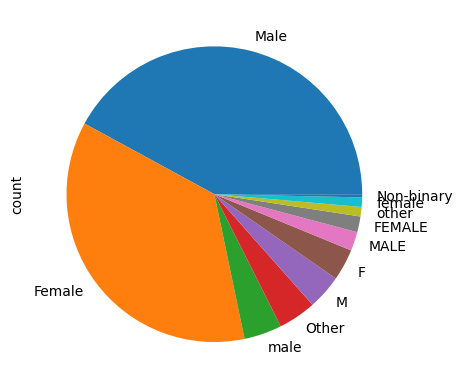

In [28]:
df['Gender'].value_counts().plot.pie()

<Axes: ylabel='count'>

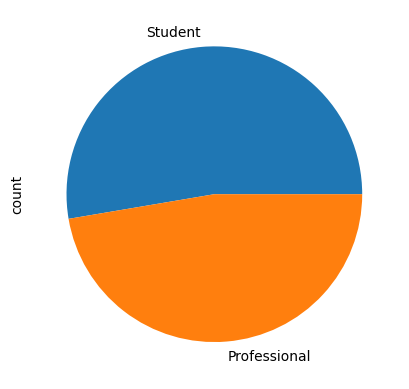

In [29]:
df['User_Type'].value_counts().plot.pie()

<Axes: ylabel='count'>

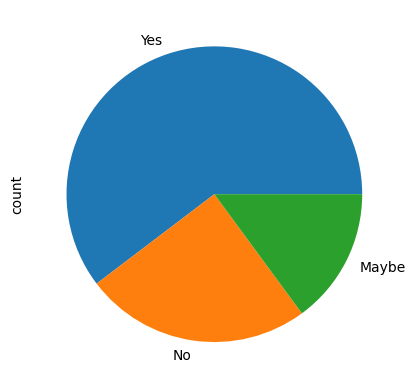

In [30]:
df['Would_Recommend'].value_counts().plot.pie()

<Axes: xlabel='Country'>

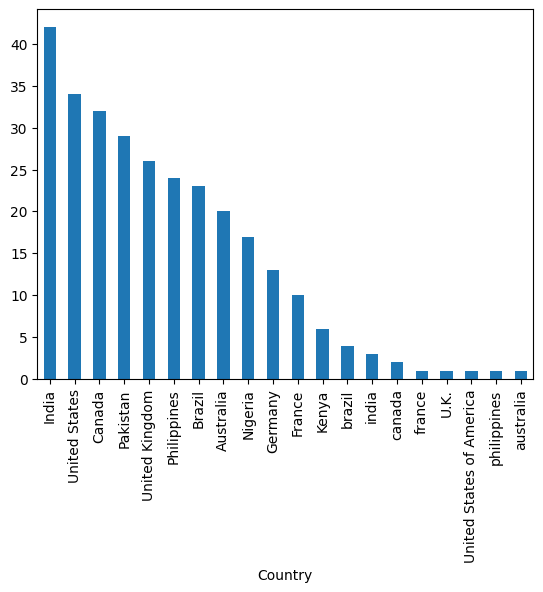

In [31]:
df['Country'].value_counts().plot.bar()

<Axes: xlabel='AI_Purpose'>

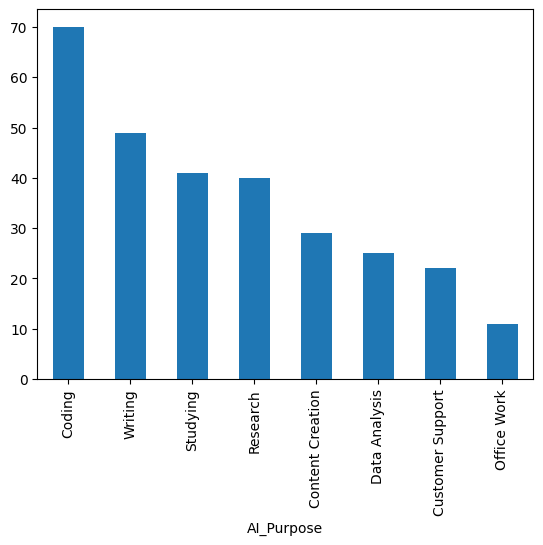

In [32]:
df['AI_Purpose'].value_counts().plot.bar()

<Axes: ylabel='Profession'>

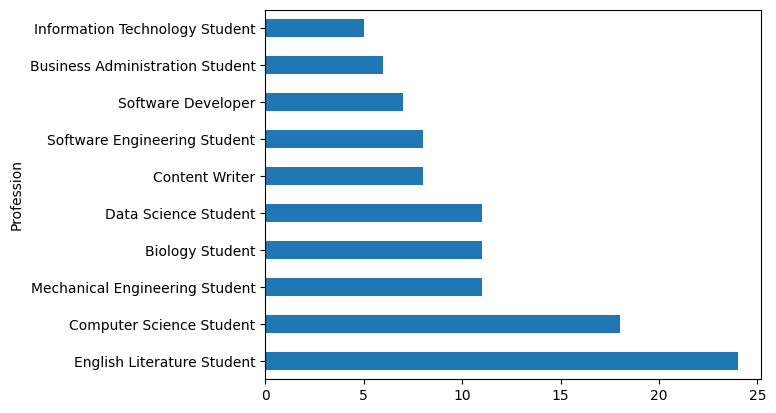

In [33]:
df['Profession'].value_counts().head(10).plot.barh()

<Axes: xlabel='User_Type'>

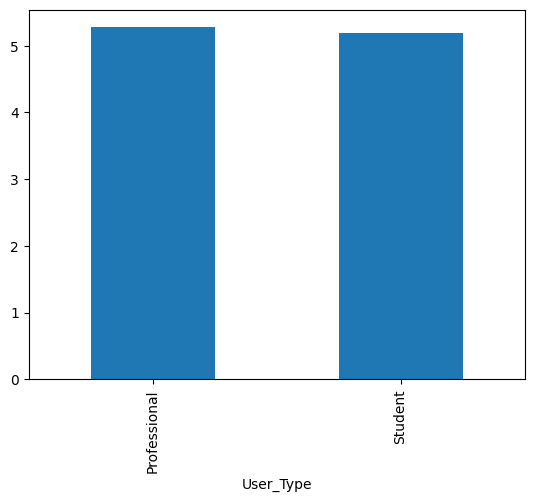

In [34]:
df.groupby('User_Type')['Productivity_Score'].mean().plot.bar()

<Axes: xlabel='Age', ylabel='Count'>

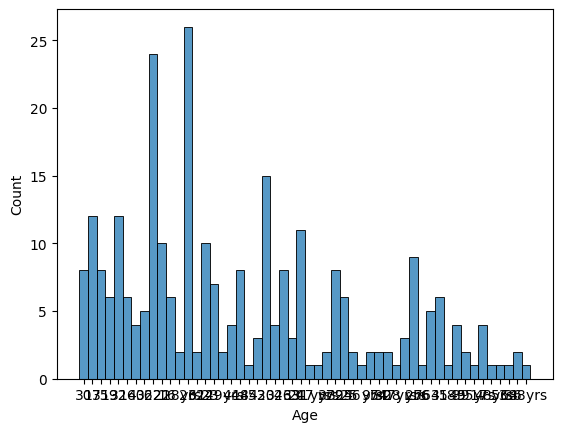

In [35]:
sns.histplot(df['Age']) 

<Axes: xlabel='Productivity_Score', ylabel='Count'>

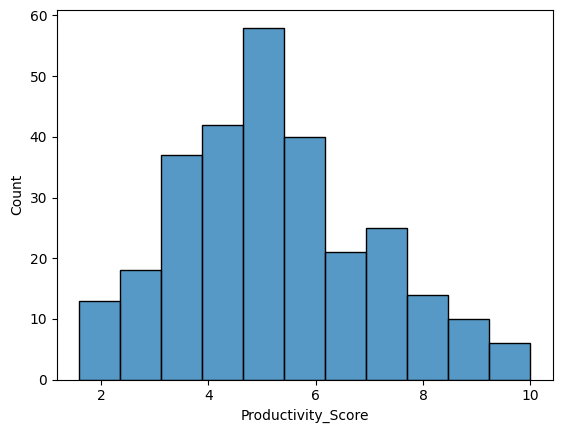

In [36]:
sns.histplot(df['Productivity_Score']) 

<Axes: xlabel='Accuracy_Rating', ylabel='Count'>

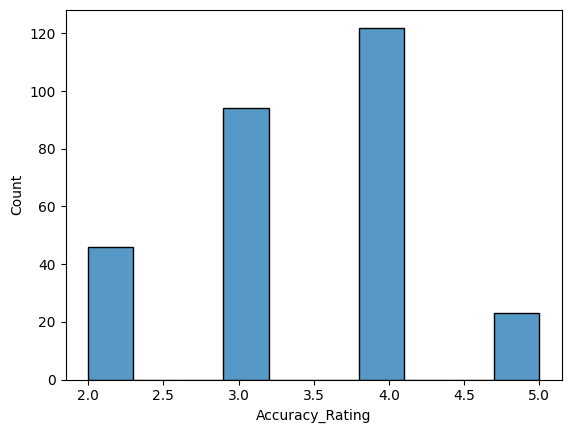

In [37]:
sns.histplot(df['Accuracy_Rating']) 

<Axes: xlabel='Satisfaction_Score', ylabel='Count'>

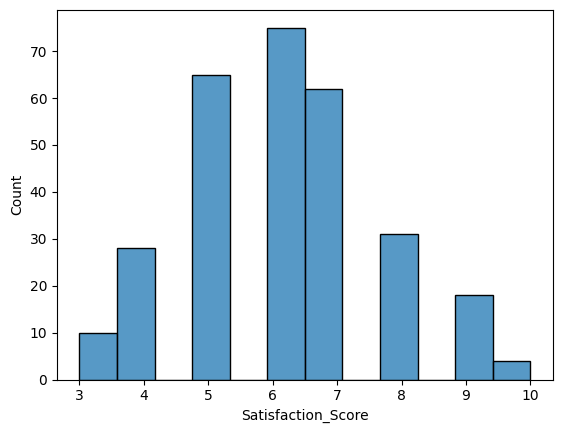

In [38]:
sns.histplot(df['Satisfaction_Score']) 

<Axes: ylabel='Density'>

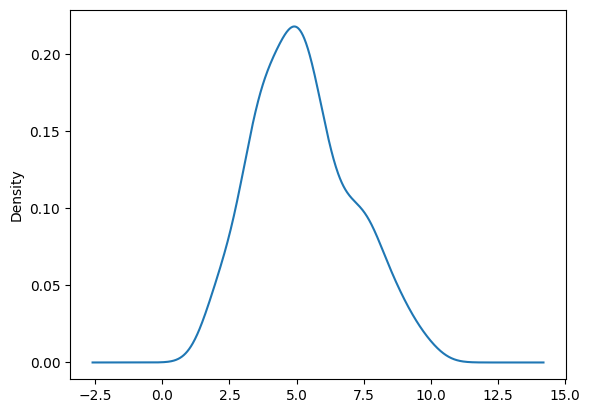

In [39]:
df['Productivity_Score'].plot.kde()


<Axes: ylabel='Density'>

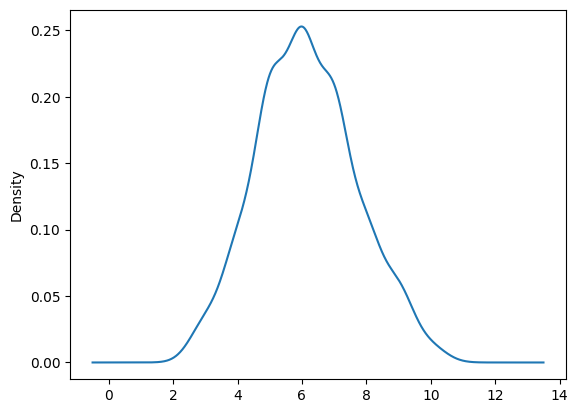

In [40]:
df['Satisfaction_Score'].plot.kde()

<Axes: ylabel='Density'>

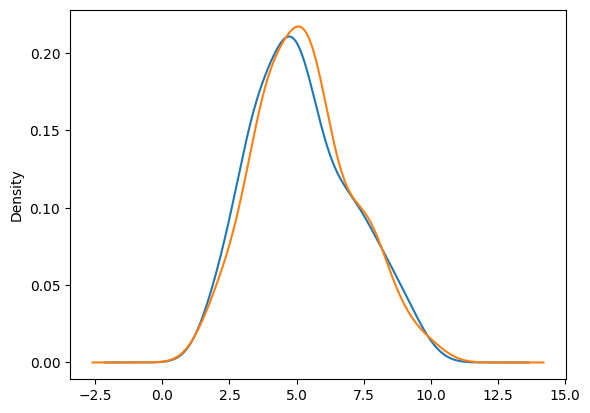

In [41]:
df[df['User_Type'] == 'Student']['Productivity_Score'].plot.kde(label='Student')

df[df['User_Type'] == 'Professional']['Productivity_Score'].plot.kde(label='Professional')

In [42]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
df = pd.read_csv("/kaggle/input/datasets/ruby1290/ai-usage-impact-on-student-and-professionals/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

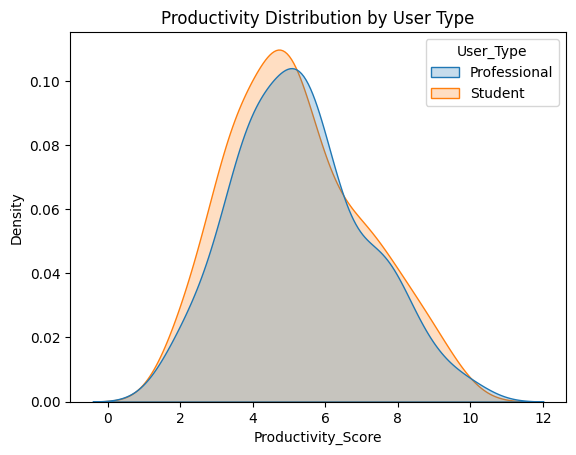

In [43]:
sns.kdeplot(data=df,x='Productivity_Score',hue='User_Type',fill=True)
plt.title('Productivity Distribution by User Type')
plt.show()

<Axes: ylabel='Productivity_Score'>

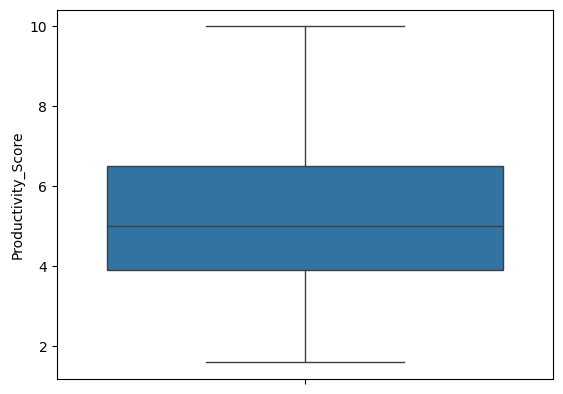

In [44]:
sns.boxplot(df['Productivity_Score'])

<Axes: ylabel='Satisfaction_Score'>

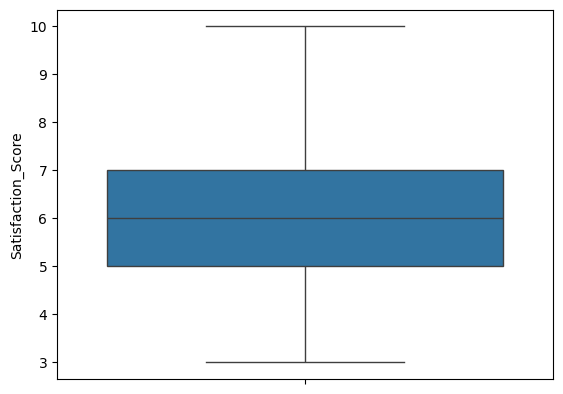

In [45]:
sns.boxplot(df['Satisfaction_Score'])

<Axes: ylabel='Accuracy_Rating'>

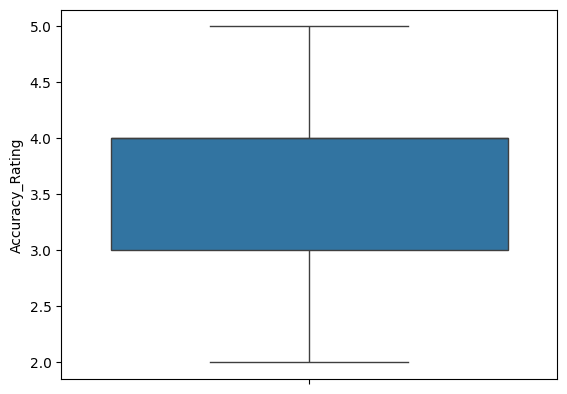

In [46]:
sns.boxplot(df['Accuracy_Rating'])

<Axes: xlabel='User_Type', ylabel='Productivity_Score'>

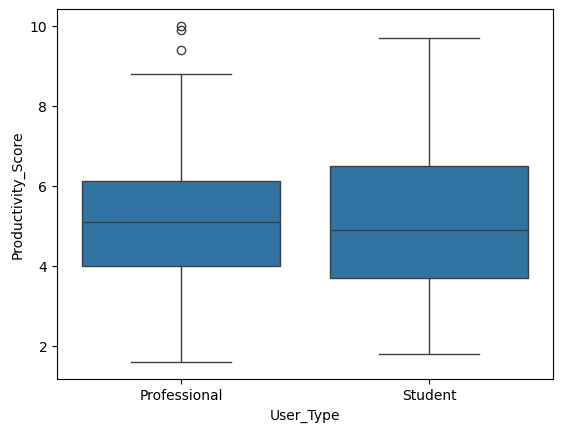

In [47]:
sns.boxplot(y='Productivity_Score', x='User_Type',data=df)

<Axes: xlabel='Gender', ylabel='Satisfaction_Score'>

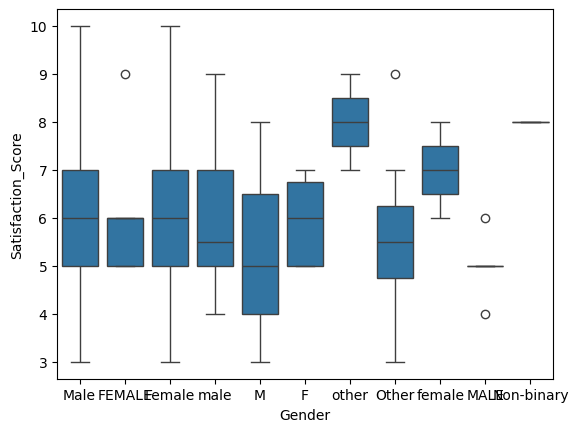

In [48]:
sns.boxplot(x='Gender', y='Satisfaction_Score',data=df)

In [49]:
Q1 = df['Productivity_Score'].quantile(0.25)
Q3 = df['Productivity_Score'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Productivity_Score'] < lower) | 
              (df['Productivity_Score'] > upper)]

outliers

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend


In [50]:
Q1 = df['Satisfaction_Score'].quantile(0.25)
Q3 = df['Satisfaction_Score'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Satisfaction_Score'] < lower) | 
              (df['Satisfaction_Score'] > upper)]

outliers

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend


In [51]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

df.groupby('User_Type')['Age'].mean()

User_Type
Professional    37.96875
Student         22.80000
Name: Age, dtype: float64

In [52]:
df.groupby('User_Type')[['Productivity_Score',
                         'Accuracy_Rating',
                         'Satisfaction_Score']].mean()

,Productivity_Score,Accuracy_Rating,Satisfaction_Score
User_Type,,,
Professional,5.276471,3.477941,6.080882
Student,5.187838,3.382550,6.203822


In [53]:
df['Productivity_Score'].agg(['min', 'max', 'mean'])

min      1.600000
max     10.000000
mean     5.230282
Name: Productivity_Score, dtype: float64

In [54]:
df['Satisfaction_Score'].agg(['min', 'max', 'mean', 'median'])

min        3.000000
max       10.000000
mean       6.146758
median     6.000000
Name: Satisfaction_Score, dtype: float64

In [55]:
df.groupby('AI_Tool')['Productivity_Score'].mean()

AI_Tool
Chat GPT             4.166667
ChatGPT              5.235514
Chatgpt              5.400000
Claude               5.278571
Copilot              7.000000
DeepSeek             5.740000
Gemini               6.500000
Google Gemini        4.955263
Grammarly            5.114286
Meta AI              5.150000
Microsoft Copilot    5.470000
Perplexity AI        4.690909
chatgpt              5.500000
claude               5.700000
copilot              5.000000
gemini               4.300000
Name: Productivity_Score, dtype: float64

In [56]:
df.groupby('AI_Tool')['Satisfaction_Score'].mean()

AI_Tool
Chat GPT             5.333333
ChatGPT              6.220183
Chatgpt              8.000000
Claude               6.103448
Copilot              6.500000
DeepSeek             6.333333
Gemini               8.000000
Google Gemini        5.666667
Grammarly            6.285714
Meta AI              6.100000
Microsoft Copilot    6.303030
Perplexity AI        5.916667
chatgpt              6.500000
claude               6.000000
copilot              6.000000
gemini                    NaN
Name: Satisfaction_Score, dtype: float64

In [57]:
df.groupby('AI_Tool')['Accuracy_Rating'].mean()

AI_Tool
Chat GPT             3.333333
ChatGPT              3.333333
Chatgpt              3.500000
Claude               3.384615
Copilot              4.000000
DeepSeek             3.888889
Gemini               3.000000
Google Gemini        3.388889
Grammarly            3.857143
Meta AI              3.500000
Microsoft Copilot    3.363636
Perplexity AI        3.434783
chatgpt              4.000000
claude               3.000000
copilot              3.000000
gemini               4.000000
Name: Accuracy_Rating, dtype: float64

In [58]:
df.groupby('AI_Purpose')['Productivity_Score'].mean()

AI_Purpose
Coding              4.908955
Content Creation    5.085185
Customer Support    5.527273
Data Analysis       5.395455
Office Work         5.945455
Research            5.413889
Studying            5.065000
Writing             5.542553
Name: Productivity_Score, dtype: float64

In [59]:
df.groupby('AI_Purpose')['Satisfaction_Score'].mean()

AI_Purpose
Coding              5.814286
Content Creation    6.000000
Customer Support    6.333333
Data Analysis       6.120000
Office Work         6.272727
Research            6.410256
Studying            6.243902
Writing             6.291667
Name: Satisfaction_Score, dtype: float64

In [60]:
df.groupby('AI_Tool')[['Productivity_Score',
                       'Accuracy_Rating',
                       'Satisfaction_Score']].agg(['min', 'max', 'mean'])

Productivity_Score                 Accuracy_Rating       \
                                 min   max      mean             min  max   
AI_Tool                                                                     
Chat GPT                         3.2   5.4  4.166667             2.0  4.0   
ChatGPT                          1.8  10.0  5.235514             2.0  5.0   
Chatgpt                          4.3   6.5  5.400000             3.0  4.0   
Claude                           2.0   8.6  5.278571             2.0  5.0   
Copilot                          6.2   7.8  7.000000             4.0  4.0   
DeepSeek                         1.6   8.9  5.740000             2.0  5.0   
Gemini                           6.5   6.5  6.500000             3.0  3.0   
Google Gemini                    1.9   9.3  4.955263             2.0  5.0   
Grammarly                        2.3   9.1  5.114286             2.0  5.0   
Meta AI                          3.3   7.8  5.150000             2.0  4.0   
Microsoft Copilot                1.8   8.6  5.470000             2.0  5.0   
Perplexity AI                    1.9   9.4  4.690909             2.0  5.0   
chatgpt                          5.2   5.8  5.500000             3.0  5.0   
claude                           5.7   5.7  5.700000             3.0  3.0   
copilot                          5.0   5.0  5.000000             3.0  3.0   
gemini                           4.3   4.3  4.300000             4.0  4.0   

                            Satisfaction_Score                  
                       mean                min   max      mean  
AI_Tool                                                         
Chat GPT           3.333333                4.0   7.0  5.333333  
ChatGPT            3.333333                3.0  10.0  6.220183  
Chatgpt            3.500000                7.0   9.0  8.000000  
Claude             3.384615                3.0   9.0  6.103448  
Copilot            4.000000                6.0   7.0  6.500000  
DeepSeek           3.888889                3.0   9.0  6.333333  
Gemini             3.000000                8.0   8.0  8.000000  
Google Gemini      3.388889                3.0   8.0  5.666667  
Grammarly          3.857143                4.0   9.0  6.285714  
Meta AI            3.500000                4.0   8.0  6.100000  
Microsoft Copilot  3.363636                4.0   9.0  6.303030  
Perplexity AI      3.434783                3.0   9.0  5.916667  
chatgpt            4.000000                5.0   8.0  6.500000  
claude             3.000000                6.0   6.0  6.000000  
copilot            3.000000                6.0   6.0  6.000000  
gemini             4.000000                NaN   NaN       NaN

In [61]:
pd.crosstab(df['Gender'], df['User_Type'])

User_Type,Professional,Student
Gender,,
F,5,5
FEMALE,3,2
Female,54,51
M,4,7
MALE,2,4
Male,56,66
Non-binary,0,1
Other,4,8
female,3,0


In [62]:
pd.crosstab(df['Gender'], df['AI_Tool'])

AI_Tool,Chat GPT,ChatGPT,Chatgpt,Claude,Copilot,DeepSeek,Gemini,Google Gemini,Grammarly,Meta AI,Microsoft Copilot,Perplexity AI,chatgpt,claude,copilot,gemini
Gender,,,,,,,,,,,,,,,,
F,0,6,0,0,0,0,0,1,0,0,2,1,0,0,0,0
FEMALE,0,3,0,0,0,0,0,0,0,1,0,1,0,0,0,0
Female,0,39,1,6,0,3,0,12,7,4,15,10,2,0,1,1
M,0,5,0,0,0,1,0,3,1,0,1,0,0,0,0,0
MALE,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0
Male,3,41,1,12,2,5,1,19,4,3,12,11,1,2,0,0
Non-binary,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Other,0,4,0,2,0,1,0,2,0,1,1,1,0,0,0,0
female,0,2,0,0,0,0,0,1,0,0,0,0,0,0,0,0


In [63]:
pd.crosstab(df['User_Type'], df['AI_Purpose'])

AI_Purpose,Coding,Content Creation,Customer Support,Data Analysis,Office Work,Research,Studying,Writing
User_Type,,,,,,,,
Professional,40,15,22,18,11,11,0,20
Student,30,14,0,7,0,29,41,29


In [64]:
pd.crosstab(df['Education_Level'], df['User_Type'])

User_Type,Professional,Student
Education_Level,,
BA/BSc,2,0
Bachelor's,50,21
Bachelors,2,0
Diploma,25,0
HS,1,0
High School,16,30
MA/MSc,1,0
Master's,30,22
Masters,2,1


In [65]:
pd.crosstab(df['Country'], df['User_Type'])

User_Type,Professional,Student
Country,,
Australia,9,11
Brazil,14,9
Canada,10,22
France,4,6
Germany,9,4
India,19,23
Kenya,3,3
Nigeria,12,5
Pakistan,12,17


In [66]:
pd.crosstab(df['Gender'], df['Would_Recommend'])

Would_Recommend,Maybe,No,Yes
Gender,,,
F,3,2,5
FEMALE,2,1,2
Female,14,24,65
M,1,5,5
MALE,2,1,3
Male,20,31,68
Non-binary,0,0,1
Other,0,5,7
female,0,1,2


In [67]:
pd.crosstab(df['Gender'], df['Would_Recommend'], normalize='index') * 100

Would_Recommend,Maybe,No,Yes
Gender,,,
F,30.000000,20.000000,50.000000
FEMALE,40.000000,20.000000,40.000000
Female,13.592233,23.300971,63.106796
M,9.090909,45.454545,45.454545
MALE,33.333333,16.666667,50.000000
Male,16.806723,26.050420,57.142857
Non-binary,0.000000,0.000000,100.000000
Other,0.000000,41.666667,58.333333
female,0.000000,33.333333,66.666667


In [68]:
pd.pivot_table(df,values='Productivity_Score',
               index='AI_Tool',
               columns='User_Type',
               aggfunc='mean')

User_Type,Professional,Student
AI_Tool,,
Chat GPT,4.650000,3.200000
ChatGPT,5.264000,5.210526
Chatgpt,4.300000,6.500000
Claude,5.508333,5.106250
Copilot,7.800000,6.200000
DeepSeek,4.440000,7.040000
Gemini,NaN,6.500000
Google Gemini,5.477778,4.485000
Grammarly,4.828571,5.400000


In [69]:
pd.pivot_table(df,
               values='Satisfaction_Score',
               index='AI_Purpose',
               columns='User_Type',
               aggfunc='mean')

User_Type,Professional,Student
AI_Purpose,,
Coding,5.900000,5.700000
Content Creation,5.909091,6.071429
Customer Support,6.333333,NaN
Data Analysis,6.388889,5.428571
Office Work,6.272727,NaN
Research,5.800000,6.620690
Studying,NaN,6.243902
Writing,6.150000,6.392857


In [70]:
pd.pivot_table(df,
               values='Accuracy_Rating',
               index='Gender',
               columns='AI_Tool',
               aggfunc='mean')

AI_Tool,Chat GPT,ChatGPT,Chatgpt,Claude,Copilot,DeepSeek,Gemini,Google Gemini,Grammarly,Meta AI,Microsoft Copilot,Perplexity AI,chatgpt,claude,copilot,gemini
Gender,,,,,,,,,,,,,,,,
F,NaN,3.500000,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,3.500000,3.000000,NaN,NaN,NaN,NaN
FEMALE,NaN,3.666667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.00,NaN,5.000000,NaN,NaN,NaN,NaN
Female,NaN,3.297297,3.0,3.25,NaN,4.0,NaN,3.500000,4.142857,3.75,3.466667,3.500000,4.5,NaN,3.0,4.0
M,NaN,3.000000,NaN,NaN,NaN,NaN,NaN,2.000000,5.000000,NaN,4.000000,NaN,NaN,NaN,NaN,NaN
MALE,NaN,3.000000,NaN,3.00,NaN,NaN,NaN,NaN,4.000000,NaN,4.000000,NaN,3.0,NaN,NaN,NaN
Male,3.333333,3.315789,4.0,3.50,4.0,3.8,3.0,3.526316,3.000000,3.00,3.083333,3.181818,4.0,3.0,NaN,NaN
Non-binary,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Other,NaN,3.750000,NaN,3.00,NaN,4.0,NaN,2.500000,NaN,4.00,3.000000,4.000000,NaN,NaN,NaN,NaN
female,NaN,2.500000,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [71]:
pd.pivot_table(df,
               values='Age',
               index='Country',
               columns='User_Type',
               aggfunc='count')

User_Type,Professional,Student
Country,,
Australia,9.0,8.0
Brazil,13.0,6.0
Canada,8.0,16.0
France,4.0,6.0
Germany,9.0,3.0
India,19.0,22.0
Kenya,2.0,3.0
Nigeria,9.0,3.0
Pakistan,12.0,15.0


In [72]:
pd.pivot_table(df,
               values=['Productivity_Score',
                       'Accuracy_Rating',
                       'Satisfaction_Score'],
               index='User_Type',
               aggfunc='mean')

,Accuracy_Rating,Productivity_Score,Satisfaction_Score
User_Type,,,
Professional,3.477941,5.276471,6.080882
Student,3.382550,5.187838,6.203822


In [73]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
df = pd.read_csv("/kaggle/input/datasets/ruby1290/ai-usage-impact-on-student-and-professionals/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

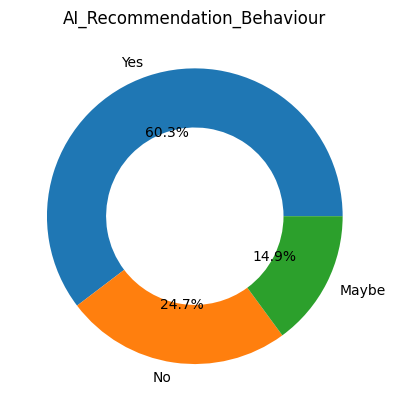

In [74]:
df['Would_Recommend'].value_counts().plot.pie(
    autopct='%1.1f%%',
    wedgeprops={'width': 0.4}
)

plt.title('AI_Recommendation_Behaviour')
plt.ylabel('')
plt.show()

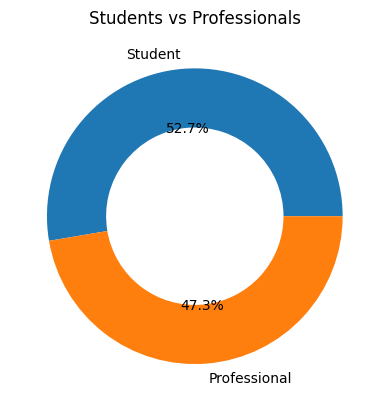

In [75]:
data = df['User_Type'].value_counts()

plt.pie(
    data,
    labels=data.index,
    autopct='%1.1f%%',
    wedgeprops={'width': 0.4}
)

plt.title('Students vs Professionals')
plt.show()

In [76]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/kaggle/input/datasets/ruby1290/ai-usage-impact-on-student-and-professionals/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

In [77]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

correlation_matrix

,Productivity_Score,Accuracy_Rating,Satisfaction_Score
Productivity_Score,1.000000,0.067571,0.651014
Accuracy_Rating,0.067571,1.000000,0.530611
Satisfaction_Score,0.651014,0.530611,1.000000


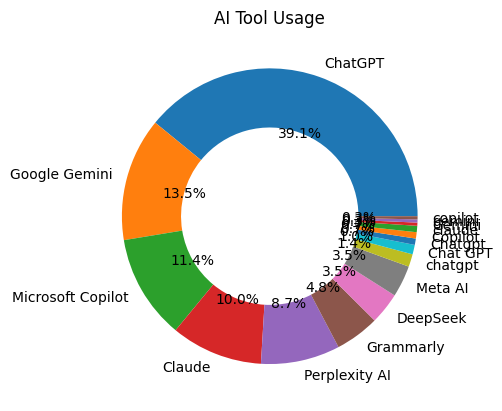

In [78]:
df['AI_Tool'].value_counts().plot.pie(
    autopct='%1.1f%%',
    wedgeprops={'width': 0.4}
)

plt.title('AI Tool Usage')
plt.ylabel('')
plt.show()

In [79]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

correlation_matrix

,Productivity_Score,Accuracy_Rating,Satisfaction_Score
Productivity_Score,1.000000,0.067571,0.651014
Accuracy_Rating,0.067571,1.000000,0.530611
Satisfaction_Score,0.651014,0.530611,1.000000


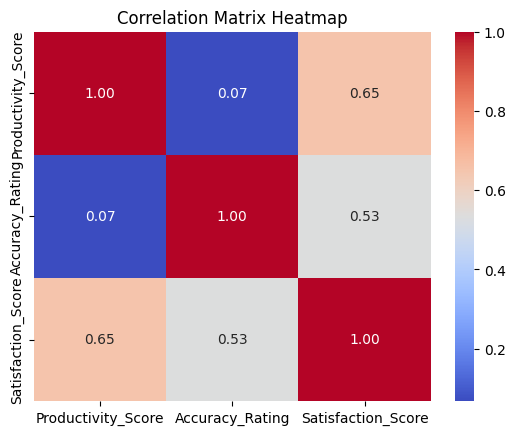

In [80]:
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix Heatmap')
plt.show()

In [81]:
corr = correlation_matrix.copy()

for i in range(len(corr.columns)):
    corr.iloc[i, i] = 0

strongest_positive = corr.stack().idxmax()

print("Variables:", strongest_positive)
print("Correlation:", corr.stack().max())

Variables: ('Productivity_Score', 'Satisfaction_Score')
Correlation: 0.6510144440208757


In [82]:
corr = correlation_matrix.copy()

for i in range(len(corr.columns)):
    corr.iloc[i, i] = 0

strongest_negative = corr.stack().idxmin()

print("Variables:", strongest_negative)
print("Correlation:", corr.stack().min())

Variables: ('Productivity_Score', 'Productivity_Score')
Correlation: 0.0


In [83]:
num_cols = [
    'Age',
    'Monthly_Income',
    'AI_Usage_Hours_Per_Day',
    'Monthly_AI_Cost',
    'Productivity_Score',
    'Accuracy_Rating',
    'Satisfaction_Score',
    'Time_Saved_Hours_Per_Week',
    'Work_or_Study_Hours_Per_Day'
]

for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r'(-?\d+\.?\d*)')[0],
        errors='coerce'
    )

numeric_df = df[num_cols]
correlation_matrix = numeric_df.corr()

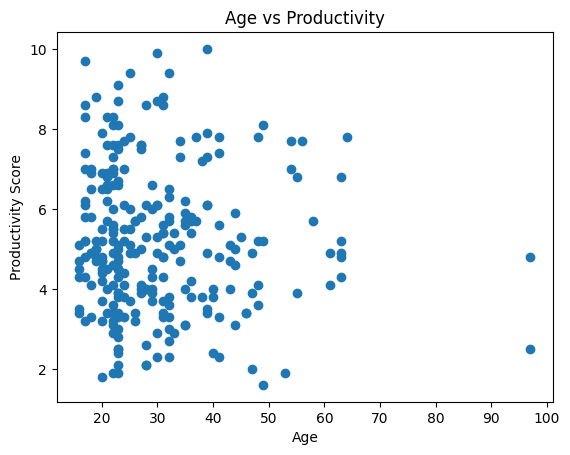

In [84]:
plt.scatter(df['Age'], df['Productivity_Score'])

plt.title('Age vs Productivity')
plt.xlabel('Age')
plt.ylabel('Productivity Score')
plt.show()

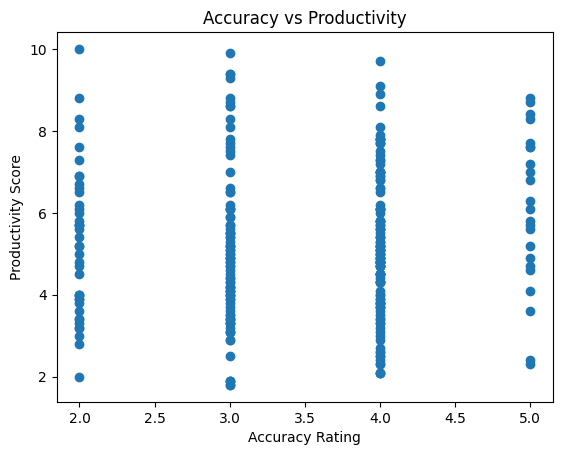

In [85]:
plt.scatter(df['Accuracy_Rating'], df['Productivity_Score'])

plt.title('Accuracy vs Productivity')
plt.xlabel('Accuracy Rating')
plt.ylabel('Productivity Score')
plt.show()

In [86]:
avg_productivity = df.groupby('AI_Tool')['Productivity_Score'].mean()

avg_productivity.to_frame('Average Productivity').style.highlight_max(
    color='lightgreen'
)

,Average Productivity
AI_Tool,
Chat GPT,4.166667
ChatGPT,5.235514
Chatgpt,5.400000
Claude,5.278571
Copilot,7.000000
DeepSeek,5.740000
Gemini,6.500000
Google Gemini,4.955263
Grammarly,5.114286


In [87]:

avg_productivity.to_frame('Average Productivity').style.highlight_min(
    color='lightcoral'
)


,Average Productivity
AI_Tool,
Chat GPT,4.166667
ChatGPT,5.235514
Chatgpt,5.400000
Claude,5.278571
Copilot,7.000000
DeepSeek,5.740000
Gemini,6.500000
Google Gemini,4.955263
Grammarly,5.114286


In [88]:
user_summary = df.groupby('User_Type')[
    ['Productivity_Score', 'Satisfaction_Score', 'Accuracy_Rating']
].mean()

user_summary.style.background_gradient(cmap='YlGnBu')

,Productivity_Score,Satisfaction_Score,Accuracy_Rating
User_Type,,,
Professional,5.276471,6.080882,3.477941
Student,5.187838,6.203822,3.382550


In [89]:
df[['User_Type', 'Productivity_Score']].style.map(
    lambda x: 'background-color: lightgreen'
    if isinstance(x, (int, float)) and x > 7 else ''
)

,User_Type,Productivity_Score
0,Professional,5.300000
1,Professional,9.900000
2,Student,3.200000
3,Professional,5.600000
4,Student,4.700000
5,Student,5.000000
6,Professional,3.000000
7,Professional,6.500000
8,Student,4.700000
9,Professional,nan


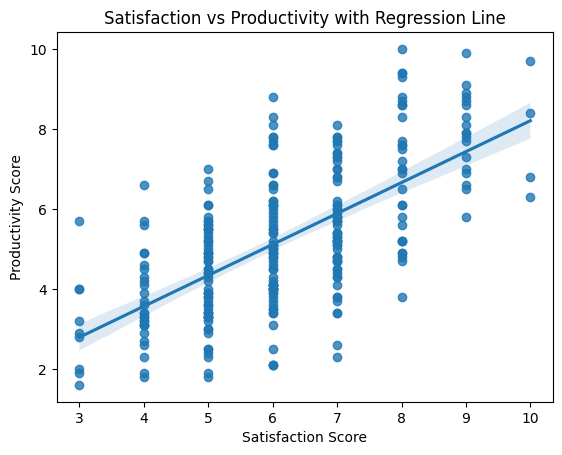

In [90]:
sns.regplot(
    data=df,
    x='Satisfaction_Score',
    y='Productivity_Score'
)

plt.title('Satisfaction vs Productivity with Regression Line')
plt.xlabel('Satisfaction Score')
plt.ylabel('Productivity Score')
plt.show()

In [91]:
correlation = df['Satisfaction_Score'].corr(
    df['Productivity_Score']
)

print("Correlation:", correlation)

Correlation: 0.651014444020875
